# SurfaceGuard AI - surface defect segmentation
Three models, one W&B run each, same data split and same metrics:
1. `scratch-unet` - small UNet written from scratch (no pretraining)
2. the pretrained model - the runner-up of a model bake-off, with an ImageNet-pretrained encoder
3. the additional model - the winner of the same bake-off, trained longest

The bake-off screens a few strong UNets (ConvNeXt-tiny / ConvNeXt-small / ConvNeXt-V2-tiny / EfficientNet-B2)
with identical settings. Optuna then tunes the winner's hyperparameters, starting from the settings that worked
best last time, and models 1 and 2 reuse them. Candidates that don't build or don't fit in GPU memory are skipped.

What the last run taught me
- ConvNeXt-tiny beat EfficientNet-B2 (0.626) and ResNet34 (0.614), so the candidates are now ConvNeXt sizes
- 5 of the 8 Optuna trials last time landed in a bad region, so the search is now narrower, starts from the best settings found so far (trial 0), and scores trials on the full validation split.
- the additional model trains 14 epochs (its validation loss was still falling at 12).

In [1]:
import os, glob, math, random, shutil, copy, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

try:
    import segmentation_models_pytorch as smp
except ImportError:
    os.system("pip install -q segmentation-models-pytorch")
    import segmentation_models_pytorch as smp

try:
    import optuna
except ImportError:
    os.system("pip install -q optuna")
    import optuna

import wandb


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.6/154.6 kB 1.7 MB/s eta 0:00:00


In [2]:
SEED = 42
H, W = 128, 800
CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
BATCH = 32
VAL_FRAC = 0.15
RLE_ORDER = "F"
WANDB_PROJECT = "surface-defect-final-run3"
WORK = "/kaggle/working"

EPOCHS = {"scratch": 6, "pretrained": 10, "additional": 14}
WD = 1e-2
ATTN = "scse"
EMA_DECAY = 0.99

N_TRIALS = 6
TUNE_EPOCHS = 3
TUNE_FRAC = 0.25
TUNE_VAL_MAX = 2000
MODEL_CHOICES = {
    "unet-convnext-tiny": ("Unet", "tu-convnext_tiny"),
    "unet-convnext-small": ("Unet", "tu-convnext_small"),
    "unet-convnextv2-tiny": ("Unet", "tu-convnextv2_tiny"),
    "unet-effb2": ("Unet", "efficientnet-b2"),
}

KNOWN_GOOD = {"lr": 7.6e-4, "enc_mult": 0.29, "cls_w": 0.26, "dice_w": 0.78, "rare_w": 1.9, "boost": 1.7}

USE_TTA = True
USE_BLOB_FILTER = True
USE_CLOSING = True
USE_AFFINE = True
USE_ENSEMBLE = True

EVAL_THR = 0.2
EVAL_CLS = 0.05
THRESHOLDS = [0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
MIN_AREAS = [0, 40, 80, 150, 300, 500, 800] if USE_BLOB_FILTER else [0]
CLS_THRESHOLDS = [0.0, 0.02, 0.05, 0.1, 0.2, 0.35, 0.5]
CLOSE_SIZES = [0, 3, 7, 13] if USE_CLOSING else [0]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
torch.backends.cudnn.benchmark = True
print("using", device)


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


seed_everything()


using cuda


In [3]:
found = glob.glob("/kaggle/input/**/train.csv", recursive=True)
assert found, "no train.csv found, is the competition data attached?"
DATA = os.path.dirname(found[0])
print("data folder:", DATA)

train_df = pd.read_csv(f"{DATA}/train.csv")
sample_sub = pd.read_csv(f"{DATA}/sample_submission.csv")
print(train_df.head())
print(sample_sub.head())

first = sample_sub["mask_rle"].iloc[0]
EMPTY_RLE = first if isinstance(first, str) else ""

img_paths = {}
for p in glob.glob(f"{DATA}/**/*", recursive=True):
    if p.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")):
        fname = os.path.basename(p)
        img_paths[fname] = p
        img_paths[os.path.splitext(fname)[0]] = p


def find_img(image_id):
    return img_paths[str(image_id)]


data folder: /kaggle/input/competitions/industrial-surface-defect-detection/public
     image_id defect_type                                           mask_rle  \
0  4S22I7SA34    defect_a  7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...   
1  4S22I7SA34    defect_b                                                NaN   
2  4S22I7SA34    defect_c                                                NaN   
3  4S22I7SA34    defect_d                                                NaN   
4  DZ899111OE    defect_a                                                NaN   

   width  height  
0    800     128  
1    800     128  
2    800     128  
3    800     128  
4    800     128  
   ID    image_id defect_type mask_rle
0   1  WAFNKCRR7Q    defect_a         
1   2  WAFNKCRR7Q    defect_b         
2   3  WAFNKCRR7Q    defect_c         
3   4  WAFNKCRR7Q    defect_d         
4   5  YZXKEWSUDD    defect_a         


In [4]:
def clean_rle(x):
    return x.strip() if isinstance(x, str) and x.strip() else ""


def rle_decode(rle, shape=(H, W)):
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    rle = clean_rle(rle)
    if rle:
        nums = [int(n) for n in rle.split()]
        for start, length in zip(nums[0::2], nums[1::2]):
            flat[start - 1:start - 1 + length] = 1
    return flat.reshape(shape, order=RLE_ORDER)


def rle_encode(mask):
    px = mask.flatten(order=RLE_ORDER)
    px = np.concatenate([[0], px, [0]])
    runs = np.where(px[1:] != px[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return " ".join(str(r) for r in runs)


real = [clean_rle(r) for r in train_df["mask_rle"] if clean_rle(r)][:200]
for r in real:
    assert rle_encode(rle_decode(r)) == r, "RLE round trip failed"
print("rle round trip ok for", len(real), "masks")

rle_by_img = {}
for img_id, g in train_df.groupby("image_id"):
    d = dict(zip(g["defect_type"], g["mask_rle"]))
    rle_by_img[img_id] = [clean_rle(d.get(c, "")) for c in CLASSES]


rle round trip ok for 200 masks


In [5]:
def load_gray(image_ids):
    out = np.zeros((len(image_ids), H, W), dtype=np.uint8)
    for k, i in enumerate(image_ids):
        img = cv2.imread(find_img(i), cv2.IMREAD_GRAYSCALE)
        assert img.shape == (H, W), f"{i} is {img.shape}, expected {(H, W)}"
        out[k] = img
    return torch.from_numpy(out)


all_ids = sorted(rle_by_img.keys())
pos_of = {i: k for k, i in enumerate(all_ids)}

X_all = load_gray(all_ids)
Y_np = np.zeros((len(all_ids), 4, H, W), dtype=np.uint8)
for k, i in enumerate(all_ids):
    for c, r in enumerate(rle_by_img[i]):
        Y_np[k, c] = rle_decode(r)
Y_all = torch.from_numpy(Y_np)

test_ids = sample_sub["image_id"].unique().tolist()
X_test = load_gray(test_ids)
print("train images:", len(all_ids), "| test images:", len(test_ids))

N_ALL = len(all_ids)
areas = torch.zeros(N_ALL, 4, dtype=torch.int64)
heat_sum = torch.zeros(4, H, W, dtype=torch.int64)
bright = np.zeros(N_ALL)
for s in range(0, N_ALL, 512):
    y = Y_all[s:s + 512]
    areas[s:s + 512] = y.flatten(2).sum(2)
    heat_sum += y.sum(0)
    bright[s:s + 512] = X_all[s:s + 512].flatten(1).sum(1).numpy() / (H * W)

present_all = (areas > 0).numpy()
n_per_img = present_all.sum(1)
short = [c[-1] for c in CLASSES]


train images: 11393 | test images: 3000


## EDA

In [6]:
rng = np.random.default_rng(SEED)
rows = []
for c in range(4):
    a = areas[:, c][areas[:, c] > 0].numpy()
    pos = np.where(present_all[:, c])[0]
    pick = rng.choice(pos, min(300, len(pos)), replace=False)
    blobs = []
    for i in pick:
        _, _, st, _ = cv2.connectedComponentsWithStats(Y_all[i, c].numpy(), connectivity=8)
        blobs.append(st[1:, cv2.CC_STAT_AREA])
    all_blobs = np.concatenate(blobs)
    rows.append({"class": CLASSES[c], "images": len(a), "share_%": round(100 * len(a) / len(all_ids), 1),
                 "median_area_px": int(np.median(a)), "p10_area_px": int(np.percentile(a, 10)),
                 "p90_area_px": int(np.percentile(a, 90)),
                 "median_blobs_per_img": int(np.median([len(b) for b in blobs])),
                 "p10_blob_px": int(np.percentile(all_blobs, 10))})
print(pd.DataFrame(rows).to_string(index=False))
print(f"\n{(n_per_img == 0).mean() * 100:.1f}% of images have no defect at all, "
      f"{(n_per_img > 1).mean() * 100:.1f}% have more than one defect type")


   class  images  share_%  median_area_px  p10_area_px  p90_area_px  median_blobs_per_img  p10_blob_px
defect_a    1081      9.5             472          160         1712                     1          119
defect_b     313      2.7             620          261         1224                     1          251
defect_c    4100     36.0            2313          571        13860                     1          217
defect_d    1707     15.0            5143         1248        15968                     1          351

48.4% of images have no defect at all, 10.5% have more than one defect type


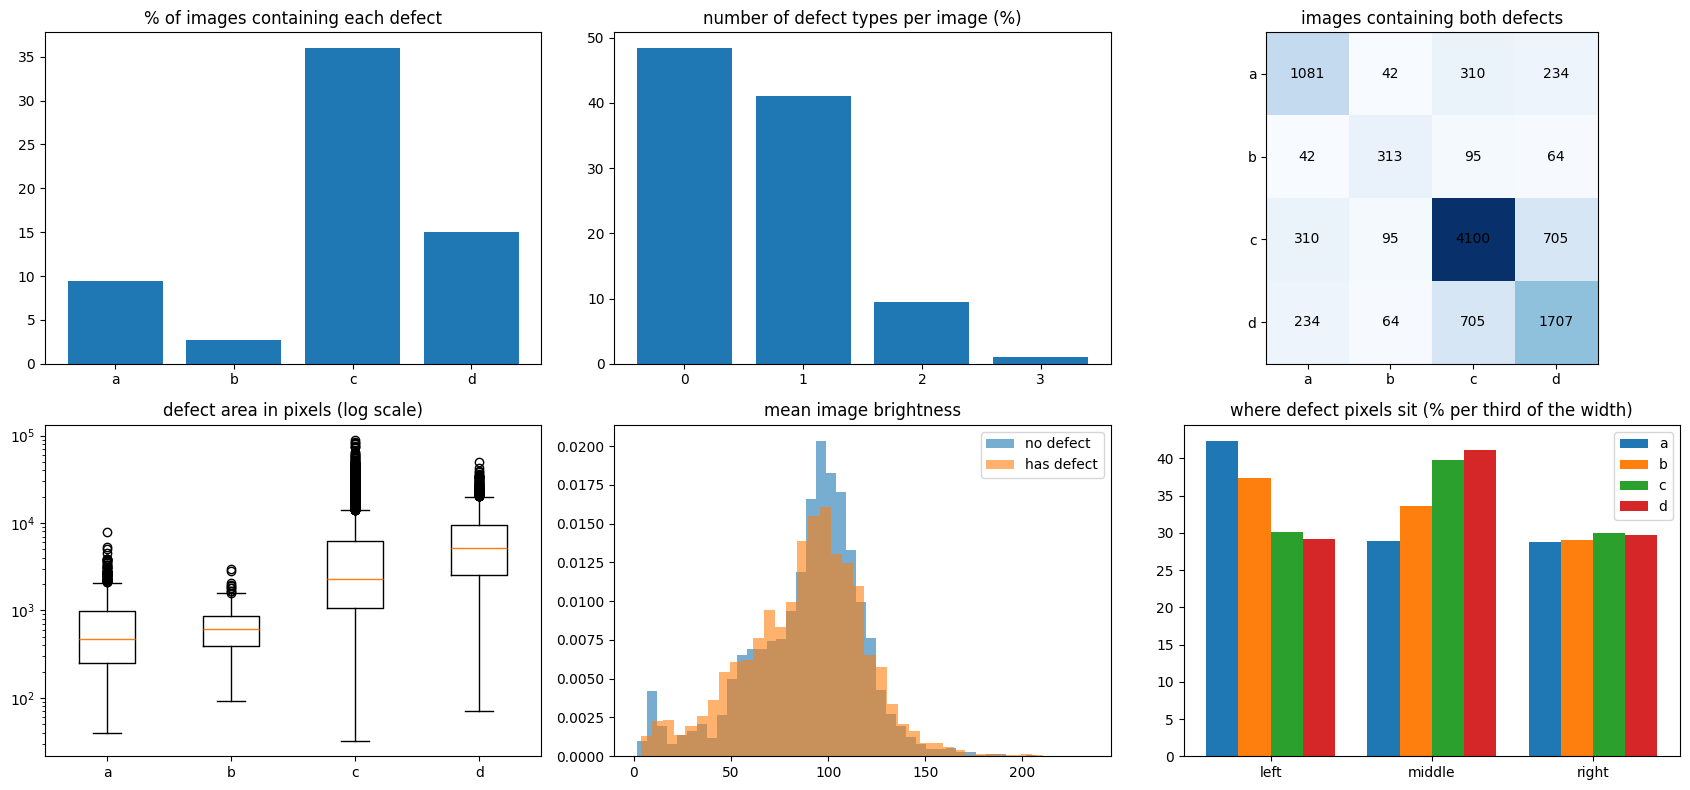

In [7]:
co = present_all.T.astype(int) @ present_all.astype(int)
heat = [heat_sum[c].numpy().astype(np.float64) for c in range(4)]
thirds = np.array([[h[:, a:b].sum() for a, b in [(0, 267), (267, 534), (534, 800)]] for h in heat])
thirds = thirds / thirds.sum(1, keepdims=True) * 100

fig, ax = plt.subplots(2, 3, figsize=(17, 8))
ax[0, 0].bar(short, present_all.mean(0) * 100)
ax[0, 0].set_title("% of images containing each defect")

counts = pd.Series(n_per_img).value_counts().sort_index()
ax[0, 1].bar(counts.index.astype(str), counts.values / len(all_ids) * 100)
ax[0, 1].set_title("number of defect types per image (%)")

ax[0, 2].imshow(co, cmap="Blues")
for i in range(4):
    for j in range(4):
        ax[0, 2].text(j, i, co[i, j], ha="center", va="center")
ax[0, 2].set_xticks(range(4))
ax[0, 2].set_xticklabels(short)
ax[0, 2].set_yticks(range(4))
ax[0, 2].set_yticklabels(short)
ax[0, 2].set_title("images containing both defects")

ax[1, 0].boxplot([areas[:, c][areas[:, c] > 0].numpy() for c in range(4)])
ax[1, 0].set_xticklabels(short)
ax[1, 0].set_yscale("log")
ax[1, 0].set_title("defect area in pixels (log scale)")

ax[1, 1].hist(bright[n_per_img == 0], bins=40, alpha=0.6, density=True, label="no defect")
ax[1, 1].hist(bright[n_per_img > 0], bins=40, alpha=0.6, density=True, label="has defect")
ax[1, 1].legend()
ax[1, 1].set_title("mean image brightness")

for c in range(4):
    ax[1, 2].bar(np.arange(3) + c * 0.2, thirds[c], width=0.2, label=short[c])
ax[1, 2].set_xticks(np.arange(3) + 0.3)
ax[1, 2].set_xticklabels(["left", "middle", "right"])
ax[1, 2].legend()
ax[1, 2].set_title("where defect pixels sit (% per third of the width)")
plt.tight_layout()
plt.show()


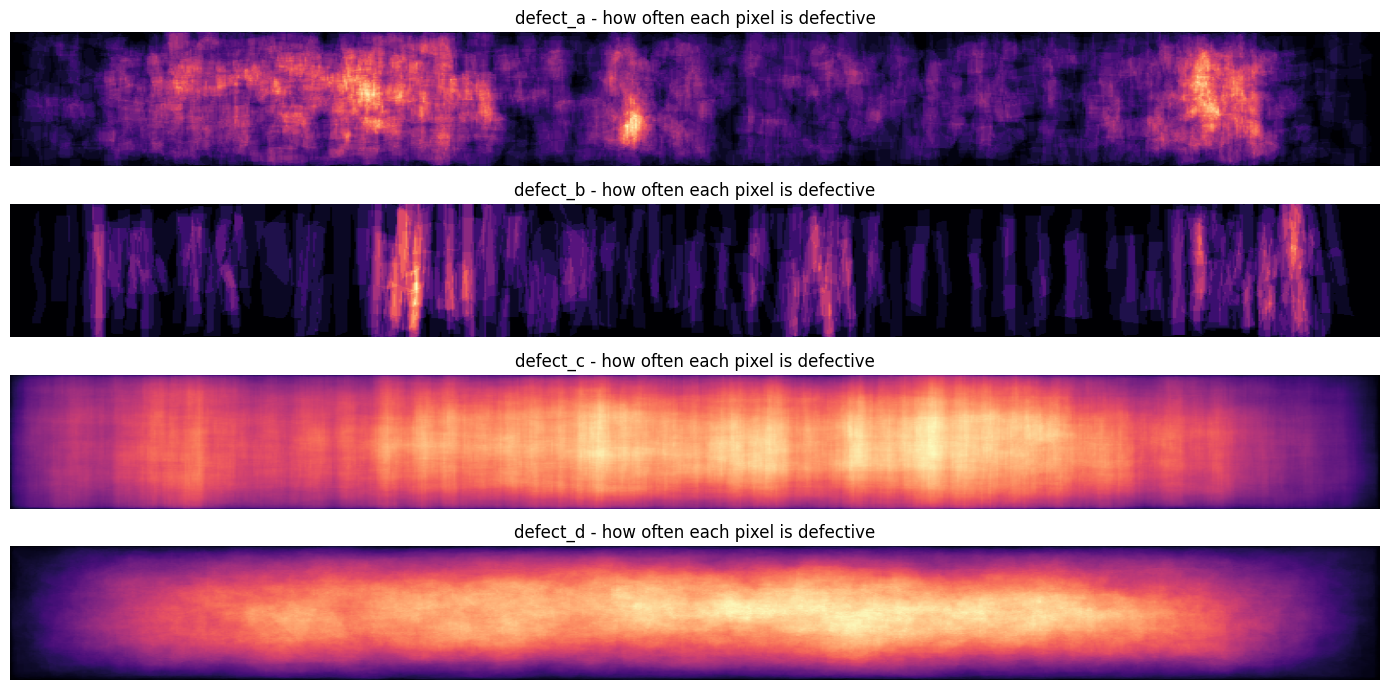

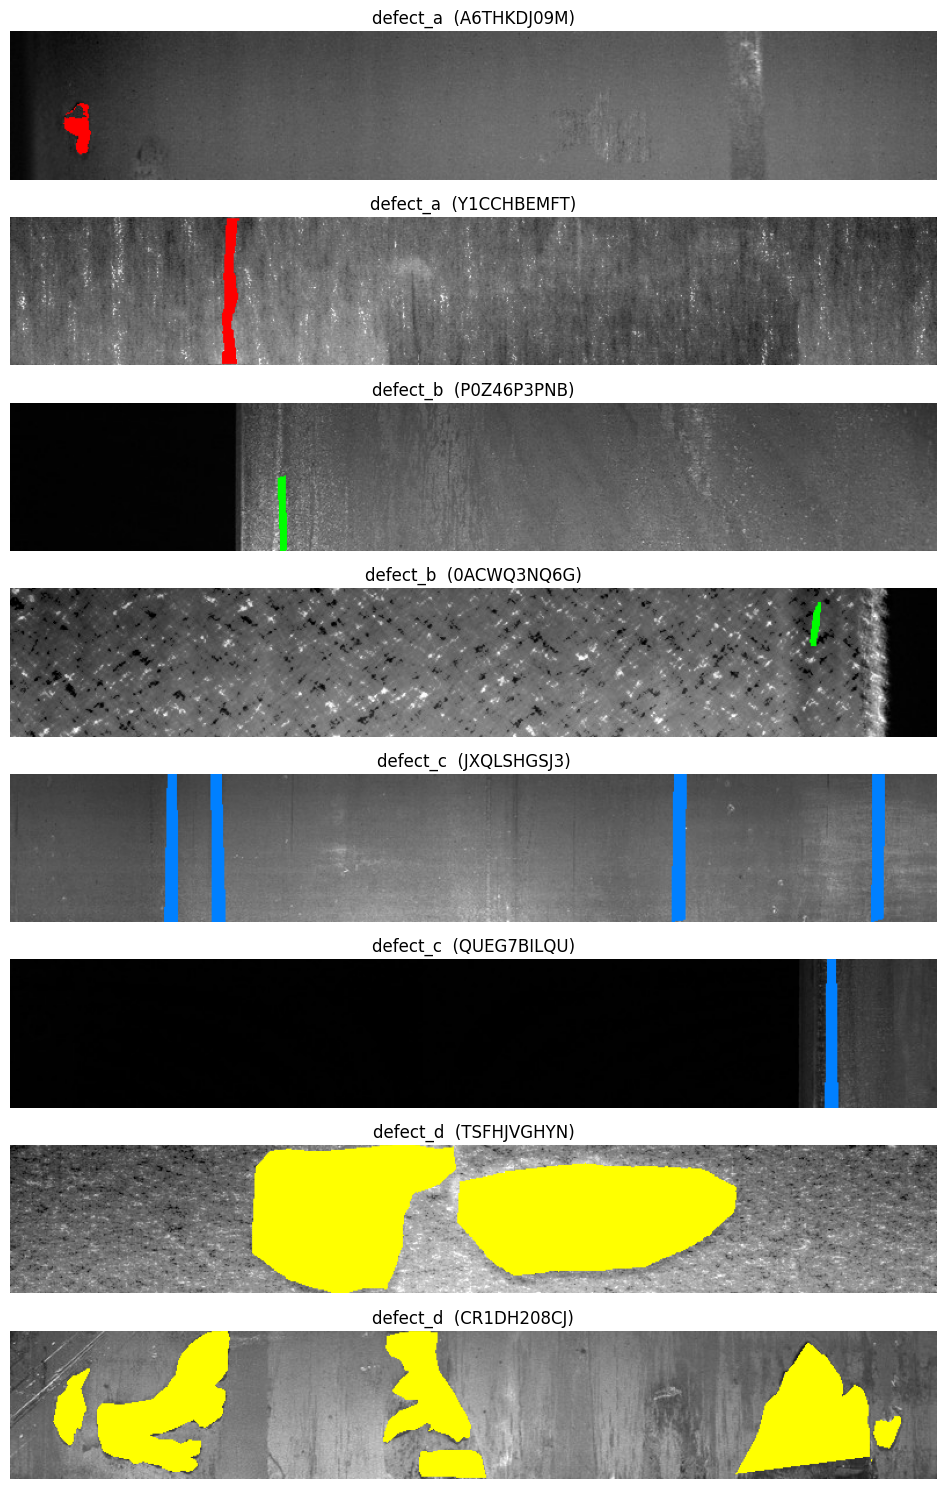

In [8]:
fig, ax = plt.subplots(4, 1, figsize=(14, 7))
for c in range(4):
    ax[c].imshow(heat[c], aspect="auto", cmap="magma")
    ax[c].set_title(f"{CLASSES[c]} - how often each pixel is defective")
    ax[c].axis("off")
plt.tight_layout()
plt.show()

colors = [(255, 0, 0), (0, 255, 0), (0, 128, 255), (255, 255, 0)]
fig, ax = plt.subplots(8, 1, figsize=(14, 15))
k = 0
for c in range(4):
    for i in rng.choice(np.where(present_all[:, c])[0], 2, replace=False):
        overlay = cv2.cvtColor(X_all[i].numpy(), cv2.COLOR_GRAY2RGB)
        overlay[Y_all[i, c].numpy() == 1] = colors[c]
        ax[k].imshow(overlay)
        ax[k].set_title(f"{CLASSES[c]}  ({all_ids[i]})")
        ax[k].axis("off")
        k += 1
plt.tight_layout()
plt.show()


In [9]:
ids = np.array(all_ids)
combo = np.array(["".join("1" if p else "0" for p in row) for row in present_all])
vc = pd.Series(combo).value_counts()
strat = np.where(vc[combo].values >= 3, combo, "rare")
if pd.Series(strat).value_counts().min() < 2:
    strat = None

train_ids, val_ids = train_test_split(ids, test_size=VAL_FRAC, random_state=SEED, stratify=strat)
train_idx = torch.tensor([pos_of[i] for i in train_ids])
val_idx = torch.tensor([pos_of[i] for i in val_ids])
print("train:", len(train_idx), "val:", len(val_idx))
print("val positives per class:", present_all[val_idx.numpy()].sum(0).tolist())

present_t = torch.from_numpy(present_all).float()
class_freq = present_t[train_idx].mean(0).clamp(min=1e-3)


def make_pos_w(boost):
    return 1.0 + boost * (present_t / class_freq.sqrt()).amax(1)


train: 9684 val: 1709
val positives per class: [162, 48, 615, 256]


In [10]:
MEAN, STD = 0.449, 0.226


def to_input(x_uint8):
    x = x_uint8.to(device).float().div(255)
    x = (x - MEAN) / STD
    return x.unsqueeze(1).repeat(1, 3, 1, 1).contiguous(memory_format=torch.channels_last)


def random_affine(x, y):
    n = x.shape[0]
    on = (torch.rand(n, device=device) < 0.5).float()
    s = 1 + torch.empty(n, device=device).uniform_(-0.1, 0.1) * on
    ang = torch.empty(n, device=device).uniform_(-3, 3) * on * math.pi / 180
    tx = torch.empty(n, device=device).uniform_(-0.08, 0.08) * on
    ty = torch.empty(n, device=device).uniform_(-0.10, 0.10) * on
    cos, sin = torch.cos(ang), torch.sin(ang)
    theta = torch.zeros(n, 2, 3, device=device)
    theta[:, 0, 0] = cos / s
    theta[:, 0, 1] = -sin / s * (H / W)
    theta[:, 0, 2] = tx
    theta[:, 1, 0] = sin / s * (W / H)
    theta[:, 1, 1] = cos / s
    theta[:, 1, 2] = ty
    grid = F.affine_grid(theta, (n, 1, H, W), align_corners=False)
    x = F.grid_sample(x.unsqueeze(1), grid, mode="bilinear", padding_mode="reflection", align_corners=False).squeeze(1)
    y = (F.grid_sample(y, grid, mode="bilinear", padding_mode="zeros", align_corners=False) > 0.5).float()
    return x, y


def get_batch(idx, augment=False):
    x = X_all[idx].to(device).float().div(255)
    y = Y_all[idx].to(device).float()
    if augment:
        n = len(idx)
        hf = torch.rand(n, device=device) < 0.5
        x[hf] = x[hf].flip(-1)
        y[hf] = y[hf].flip(-1)
        vf = torch.rand(n, device=device) < 0.5
        x[vf] = x[vf].flip(-2)
        y[vf] = y[vf].flip(-2)
        a = torch.empty(n, 1, 1, device=device).uniform_(0.85, 1.15)
        b = torch.empty(n, 1, 1, device=device).uniform_(-0.05, 0.05)
        jit = torch.rand(n, 1, 1, device=device) < 0.5
        x = torch.where(jit, (x * a + b).clamp(0, 1), x)
        if USE_AFFINE:
            x, y = random_affine(x, y)
    x = (x - MEAN) / STD
    x = x.unsqueeze(1).repeat(1, 3, 1, 1).contiguous(memory_format=torch.channels_last)
    return x, y


AUGS = ("hflip, vflip, brightness/contrast jitter, light random affine (scale/shift/rotate), "
        "rare-class oversampling")


In [11]:
def double_conv(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
    )


class SmallUNet(nn.Module):
    def __init__(self, in_ch=3, n_cls=4, base=24):
        super().__init__()
        b = base
        self.enc1 = double_conv(in_ch, b)
        self.enc2 = double_conv(b, b * 2)
        self.enc3 = double_conv(b * 2, b * 4)
        self.enc4 = double_conv(b * 4, b * 8)
        self.mid = double_conv(b * 8, b * 16)
        self.pool = nn.MaxPool2d(2)

        self.up4 = nn.ConvTranspose2d(b * 16, b * 8, 2, stride=2)
        self.dec4 = double_conv(b * 16, b * 8)
        self.up3 = nn.ConvTranspose2d(b * 8, b * 4, 2, stride=2)
        self.dec3 = double_conv(b * 8, b * 4)
        self.up2 = nn.ConvTranspose2d(b * 4, b * 2, 2, stride=2)
        self.dec2 = double_conv(b * 4, b * 2)
        self.up1 = nn.ConvTranspose2d(b * 2, b, 2, stride=2)
        self.dec1 = double_conv(b * 2, b)
        self.out = nn.Conv2d(b, n_cls, 1)
        self.cls_head = nn.Sequential(nn.Dropout(0.2), nn.Linear(b * 16, n_cls))

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        m = self.mid(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(m), e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.out(d1), self.cls_head(m.mean((2, 3)))


def build_unet(encoder, attn=ATTN, arch="Unet"):
    return getattr(smp, arch)(encoder, encoder_weights="imagenet", in_channels=3, classes=4,
                              aux_params={"classes": 4, "dropout": 0.2},
                              decoder_attention_type=None if attn == "none" else attn)


def try_build(arch, encoder):
    try:
        m = build_unet(encoder, arch=arch).to(device).eval()
        with torch.no_grad():
            seg, cls = m(torch.zeros(1, 3, H, W, device=device))
        assert tuple(seg.shape[-2:]) == (H, W) and cls.shape[-1] == 4
        return m
    except Exception as e:
        print(f"  {arch} + {encoder} can't be used here: {str(e)[:100]}")
        return None


In [12]:
def total_loss(seg, cls, y, hp):
    cw = torch.tensor([hp["rare_w"], hp["rare_w"], 1.0, 1.0], device=seg.device)
    bce = (F.binary_cross_entropy_with_logits(seg, y, reduction="none").mean((0, 2, 3)) * cw).sum() / cw.sum()

    p = torch.sigmoid(seg)
    inter = (p * y).sum((0, 2, 3))
    total = p.sum((0, 2, 3)) + y.sum((0, 2, 3))
    dice_loss = ((1 - (2 * inter + 1) / (total + 1)) * cw).sum() / cw.sum()

    present = (y.amax(dim=(2, 3)) > 0).float()
    cls_loss = (F.binary_cross_entropy_with_logits(cls, present, reduction="none").mean(0) * cw).sum() / cw.sum()
    return bce + hp["dice_w"] * dice_loss + hp["cls_w"] * cls_loss


def pair_stats(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    return (pred & gt).sum((2, 3)), pred.sum((2, 3)), gt.sum((2, 3))


def scores_from_stats(inter, parea, garea):
    inter, parea, garea = np.asarray(inter).ravel(), np.asarray(parea).ravel(), np.asarray(garea).ravel()
    empty = garea == 0
    dice = 2 * inter / np.maximum(parea + garea, 1)
    fg = dice[~empty].mean() if (~empty).any() else 0.0
    fp = (parea[empty] == 0).mean() if empty.any() else 1.0
    acc = ((parea == 0) == empty).mean()
    return {"fg_dice": float(fg), "fp_score": float(fp), "empty_acc": float(acc),
            "weighted": float(0.7 * fg + 0.2 * fp + 0.1 * acc)}


def class_scores(I, P, G):
    return [scores_from_stats(I[:, c], P[:, c], G[:, c]) for c in range(4)]


def class_report(masks, gts):
    I, P, G = pair_stats(masks, gts)
    rows = []
    for c, s in enumerate(class_scores(I, P, G)):
        pos = G[:, c] > 0
        found = pos & (P[:, c] > 0)
        dice = 2 * I[:, c] / np.maximum(P[:, c] + G[:, c], 1)
        rows.append({"class": CLASSES[c], "positives": int(pos.sum()),
                     "found_%": round(100 * found.sum() / max(pos.sum(), 1), 1),
                     "dice_if_found": round(float(dice[found].mean()), 4) if found.any() else 0.0,
                     **{k: round(v, 4) for k, v in s.items()}})
    return pd.DataFrame(rows)


def macro_of(report):
    return report[["fg_dice", "fp_score", "empty_acc", "weighted"]].mean().to_dict()


@torch.no_grad()
def evaluate(model, idx, hp):
    model.eval()
    loss_sum, n = 0.0, 0
    inters, pareas, gareas = [], [], []
    for s in range(0, len(idx), 64):
        b = idx[s:s + 64]
        x, y = get_batch(b)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            seg, cls = model(x)
        seg, cls = seg.float(), cls.float()
        loss_sum += total_loss(seg, cls, y, hp).item() * len(b)
        n += len(b)
        pred = (torch.sigmoid(seg) > EVAL_THR) & (torch.sigmoid(cls) > EVAL_CLS)[:, :, None, None]
        yb = y > 0.5
        inters.append((pred & yb).sum((2, 3)).cpu())
        pareas.append(pred.sum((2, 3)).cpu())
        gareas.append(yb.sum((2, 3)).cpu())
    I, P, G = torch.cat(inters).numpy(), torch.cat(pareas).numpy(), torch.cat(gareas).numpy()
    per = class_scores(I, P, G)
    sc = {k: float(np.mean([s[k] for s in per])) for k in ["fg_dice", "fp_score", "empty_acc", "weighted"]}
    for c in range(4):
        sc[f"dice_{short[c]}"] = per[c]["fg_dice"]
    return loss_sum / n, sc


class EMA:
    def __init__(self, model, decay=EMA_DECAY):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay
        self.steps = 0

    @torch.no_grad()
    def update(self, model):
        self.steps += 1
        d = min(self.decay, (1 + self.steps) / (10 + self.steps))
        src = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(src[k].detach(), alpha=1 - d)
            else:
                v.copy_(src[k])


def fit(model, hp, epochs, tr_idx, va_idx, ckpt_path=None, on_epoch=None):
    enc_params = [p for n, p in model.named_parameters() if n.startswith("encoder.")]
    other_params = [p for n, p in model.named_parameters() if not n.startswith("encoder.")]
    if enc_params:
        enc_lr = hp["lr"] * hp.get("enc_mult", 1.0)
        groups = [{"params": enc_params, "lr": enc_lr}, {"params": other_params, "lr": hp["lr"]}]
        max_lrs = [enc_lr, hp["lr"]]
    else:
        groups = [{"params": other_params, "lr": hp["lr"]}]
        max_lrs = hp["lr"]
    opt = torch.optim.AdamW(groups, weight_decay=hp["wd"])
    steps = len(tr_idx) // BATCH
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=max_lrs, total_steps=epochs * steps, pct_start=0.15)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    weights = make_pos_w(hp["boost"])[tr_idx]
    ema = EMA(model)

    history, best_score, best_epoch = [], -1.0, 0
    for ep in range(1, epochs + 1):
        model.train()
        order = tr_idx[torch.multinomial(weights, len(tr_idx), replacement=True)]
        loss_sum, n = 0.0, 0
        for s in range(steps):
            b = order[s * BATCH:(s + 1) * BATCH]
            x, y = get_batch(b, augment=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                seg, cls = model(x)
            loss = total_loss(seg.float(), cls.float(), y, hp)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            ema.update(model)
            loss_sum += loss.item() * len(b)
            n += len(b)

        train_loss = loss_sum / n
        val_loss, sc = evaluate(ema.module, va_idx, hp)
        history.append({"epoch": ep, "train_loss": train_loss, "val_loss": val_loss, **sc})
        print(f"epoch {ep}/{epochs}  train {train_loss:.4f}  val {val_loss:.4f}  score {sc['weighted']:.4f}  "
              f"dice [a {sc['dice_a']:.2f} b {sc['dice_b']:.2f} c {sc['dice_c']:.2f} d {sc['dice_d']:.2f}]")
        if on_epoch is not None:
            on_epoch(ep, train_loss, val_loss, sc, opt.param_groups[-1]["lr"])

        if sc["weighted"] > best_score:
            best_score, best_epoch = sc["weighted"], ep
            if ckpt_path is not None:
                torch.save(ema.module.state_dict(), ckpt_path)
    return history, best_epoch, best_score


In [13]:
FLIPS = [[], [-1]] if USE_TTA else [[]]


@torch.no_grad()
def get_probs(models, x):
    seg_sum, cls_sum, count = 0, 0, 0
    for m in models:
        for dims in FLIPS:
            xin = torch.flip(x, dims=dims) if dims else x
            with torch.autocast(device_type=device.type, enabled=use_amp):
                seg, cls = m(xin)
            seg, cls = torch.sigmoid(seg.float()), torch.sigmoid(cls.float())
            if dims:
                seg = torch.flip(seg, dims=dims)
            seg_sum = seg_sum + seg
            cls_sum = cls_sum + cls
            count += 1
    return seg_sum / count, cls_sum / count


@torch.no_grad()
def predict_val(models):
    for m in models:
        m.eval()
    segs, clss = [], []
    for s in range(0, len(val_idx), 64):
        b = val_idx[s:s + 64]
        seg, cls = get_probs(models, to_input(X_all[b]))
        segs.append(seg.cpu().numpy().astype(np.float16))
        clss.append(cls.cpu().numpy())
    return np.concatenate(segs), np.concatenate(clss), Y_all[val_idx].numpy()


def remove_small(mask, min_area):
    if min_area <= 0 or not mask.any():
        return mask
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    out = np.zeros_like(mask)
    for k in range(1, n):
        if stats[k, cv2.CC_STAT_AREA] >= min_area:
            out[labels == k] = 1
    return out


def close_gaps(mask, k):
    if k <= 0 or not mask.any():
        return mask
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    return cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE, kernel)


def make_masks(prob, thr, area, close_k):
    binary = (prob > thr).astype(np.uint8)
    return np.stack([remove_small(close_gaps(b, close_k), area) for b in binary])


def tune_on_val(seg, cls, gts):
    params = []
    for c in range(4):
        g = gts[:, c:c + 1]
        garea = g.sum((2, 3))
        best = {"score": -1, "thr": 0.5, "min_area": 0, "cls_thr": 0.5, "close": 0}
        for thr in THRESHOLDS:
            binary = (seg[:, c] > thr).astype(np.uint8)
            for area in MIN_AREAS:
                m = binary if area == 0 else np.stack([remove_small(b, area) for b in binary])
                inter, parea, _ = pair_stats(m[:, None], g)
                for ct in CLS_THRESHOLDS:
                    keep = (cls[:, c] > ct)[:, None]
                    s = scores_from_stats(inter * keep, parea * keep, garea)["weighted"]
                    if s > best["score"]:
                        best = {"score": s, "thr": thr, "min_area": area, "cls_thr": ct, "close": 0}
        keep = (cls[:, c] > best["cls_thr"])[:, None]
        for k in CLOSE_SIZES[1:]:
            m = make_masks(seg[:, c], best["thr"], best["min_area"], k)
            inter, parea, _ = pair_stats(m[:, None], g)
            s = scores_from_stats(inter * keep, parea * keep, garea)["weighted"]
            if s > best["score"]:
                best["score"], best["close"] = s, k
        params.append({"thr": best["thr"], "min_area": best["min_area"], "cls_thr": best["cls_thr"],
                       "close": best["close"]})
        print(f"  {CLASSES[c]}: thr={best['thr']} min_area={best['min_area']} cls_thr={best['cls_thr']} "
              f"close={best['close']} val_score={best['score']:.4f}")
    return params


def apply_post(seg, cls, params):
    out = np.zeros(seg.shape, dtype=np.uint8)
    for c in range(4):
        cleaned = make_masks(seg[:, c], params[c]["thr"], params[c]["min_area"], params[c]["close"])
        keep = cls[:, c] > params[c]["cls_thr"]
        out[:, c] = cleaned * keep[:, None, None]
    return out


@torch.no_grad()
def predict_test(models, params):
    for m in models:
        m.eval()
    preds = {}
    for s in range(0, len(test_ids), 64):
        seg, cls = get_probs(models, to_input(X_test[s:s + 64]))
        masks = apply_post(seg.cpu().numpy(), cls.cpu().numpy(), params)
        for b in range(masks.shape[0]):
            for c in range(4):
                m = masks[b, c]
                preds[(test_ids[s + b], CLASSES[c])] = rle_encode(m) if m.any() else EMPTY_RLE
    return preds


def write_submission(preds, path):
    sub = sample_sub.copy()
    sub["mask_rle"] = [preds.get((i, d), EMPTY_RLE) for i, d in zip(sub["image_id"], sub["defect_type"])]
    assert list(sub.columns) == list(sample_sub.columns)
    assert len(sub) == len(sample_sub)
    assert (sub["ID"].values == sample_sub["ID"].values).all()
    assert not sub.duplicated(["image_id", "defect_type"]).any()
    sub.to_csv(path, index=False)


In [14]:
from kaggle_secrets import UserSecretsClient

wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: amitoj (24f2002444) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

## Choosing the additional model, then tuning it
Stage 1 (bake-off): every candidate model gets the same short training run with the same settings on a quarter
of the training images, and the best on the class-averaged validation score becomes the additional model.
Candidates that don't build or don't fit in GPU memory are skipped.
Stage 2 (Optuna): the winner's learning rate, encoder learning-rate multiplier (`enc_mult`), loss weights,
rare-class weighting (`rare_w`) and rare-class sampling (`boost`) are tuned. Weak trials get pruned early.
Models 1 and 2 reuse the tuned settings.

screening uses 2421 train images and 1709 val images

--- unet-convnext-tiny: Unet with tu-convnext_tiny ---


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1/3  train 1.4226  val 1.0620  score 0.1935  dice [a 0.00 b 0.00 c 0.12 d 0.31]
epoch 2/3  train 0.8979  val 0.8399  score 0.3839  dice [a 0.10 b 0.05 c 0.45 d 0.62]
epoch 3/3  train 0.7703  val 0.7838  score 0.4843  dice [a 0.27 b 0.15 c 0.51 d 0.68]

--- unet-convnext-small: Unet with tu-convnext_small ---


model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 36.8MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1/3  train 1.3035  val 1.0375  score 0.1279  dice [a 0.02 b 0.00 c 0.25 d 0.29]
epoch 2/3  train 0.8595  val 0.8559  score 0.2926  dice [a 0.07 b 0.00 c 0.41 d 0.44]
epoch 3/3  train 0.7838  val 0.8197  score 0.3369  dice [a 0.10 b 0.00 c 0.44 d 0.50]

              variant  score  dice_a  dice_b  dice_c  dice_d  val_loss
  unet-convnext-tiny 0.4843  0.2727   0.154  0.5079  0.6772    0.7838
unet-convnextv2-tiny 0.4156  0.0000   0.000  0.4673  0.6323    0.8086
 unet-convnext-small 0.3792  0.0000   0.000  0.4655  0.6477    0.7580
          unet-effb2 0.3369  0.1022   0.000  0.4435  0.4967    0.8197

additional model (longest run): unet-convnext-tiny (Unet with tu-convnext_tiny)
pretrained model (runner-up): unet-convnextv2-tiny (Unet with tu-convnextv2_tiny)


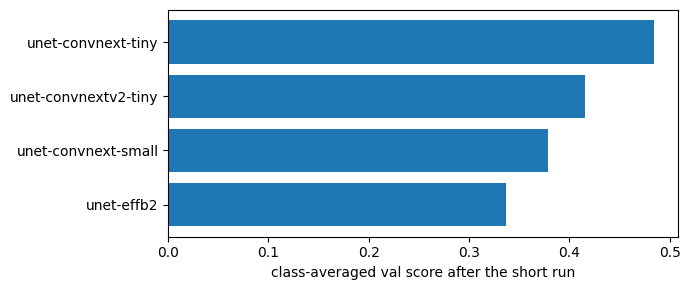

In [15]:
rng_t = np.random.default_rng(SEED)
tune_idx = train_idx[torch.from_numpy(rng_t.permutation(len(train_idx))[: int(len(train_idx) * TUNE_FRAC)])]
tune_val_idx = val_idx[:TUNE_VAL_MAX]
print("screening uses", len(tune_idx), "train images and", len(tune_val_idx), "val images")

HP0 = {**KNOWN_GOOD, "wd": WD}

bake_rows = []
for variant, (arch, encoder) in MODEL_CHOICES.items():
    print(f"\n--- {variant}: {arch} with {encoder} ---")
    seed_everything(SEED)
    model = try_build(arch, encoder)
    if model is None:
        continue
    model = model.to(memory_format=torch.channels_last)
    try:
        history, best_ep, best_score = fit(model, HP0, TUNE_EPOCHS, tune_idx, tune_val_idx)
    except torch.cuda.OutOfMemoryError:
        print("  ran out of GPU memory, skipping it")
        continue
    finally:
        del model
        torch.cuda.empty_cache()
    row = history[best_ep - 1]
    bake_rows.append({"variant": variant, "score": best_score, "dice_a": row["dice_a"], "dice_b": row["dice_b"],
                      "dice_c": row["dice_c"], "dice_d": row["dice_d"], "val_loss": row["val_loss"]})

assert bake_rows, "none of the candidate models could be trained here"
bakeoff = pd.DataFrame(bake_rows).sort_values("score", ascending=False).reset_index(drop=True).round(4)
bakeoff.to_csv(f"{WORK}/model_bakeoff.csv", index=False)
print("\n", bakeoff.to_string(index=False))

extra_variant = bakeoff["variant"].iloc[0]
extra_arch, extra_enc = MODEL_CHOICES[extra_variant]
extra_name = f"{extra_enc}-{extra_arch.lower()}"

second_variant = bakeoff["variant"].iloc[1] if len(bakeoff) > 1 else "unet-effb2"
second_arch, second_enc = MODEL_CHOICES[second_variant]
second_name = f"pretrained-{second_enc}-{second_arch.lower()}"
print("\nadditional model (longest run):", extra_variant, f"({extra_arch} with {extra_enc})")
print("pretrained model (runner-up):", second_variant, f"({second_arch} with {second_enc})")

plt.figure(figsize=(7, 3))
plt.barh(bakeoff["variant"][::-1], bakeoff["score"][::-1])
plt.xlabel("class-averaged val score after the short run")
plt.tight_layout()
plt.savefig(f"{WORK}/model_bakeoff.png", dpi=120)
plt.show()


[I 2026-11-12 04:12:50,053] A new study created in memory with name: no-name-30f00cdd-077a-4eb1-9fd4-8fcb6be9cf7b


epoch 1/3  train 1.4226  val 1.0620  score 0.1935  dice [a 0.00 b 0.00 c 0.12 d 0.31]
epoch 2/3  train 0.8979  val 0.8399  score 0.3839  dice [a 0.10 b 0.05 c 0.45 d 0.62]


[I 2026-11-12 04:15:39,595] Trial 0 finished with value: 0.48434704649486576 and parameters: {'lr': 0.00076, 'enc_mult': 0.29, 'cls_w': 0.26, 'dice_w': 0.78, 'rare_w': 1.9, 'boost': 1.7}. Best is trial 0 with value: 0.48434704649486576.


epoch 3/3  train 0.7703  val 0.7838  score 0.4843  dice [a 0.27 b 0.15 c 0.51 d 0.68]
epoch 1/3  train 1.9260  val 1.6411  score 0.1487  dice [a 0.01 b 0.01 c 0.09 d 0.12]
epoch 2/3  train 1.3724  val 1.2615  score 0.3179  dice [a 0.06 b 0.03 c 0.28 d 0.53]


[I 2026-11-12 04:18:28,825] Trial 1 finished with value: 0.38436652686709705 and parameters: {'lr': 0.0005042162933217114, 'enc_mult': 0.4802857225639665, 'cls_w': 0.4659969709057026, 'dice_w': 1.0986584841970366, 'rare_w': 1.312037280884873, 'boost': 1.0651906845715446}. Best is trial 0 with value: 0.48434704649486576.


epoch 3/3  train 1.1977  val 1.1942  score 0.3844  dice [a 0.03 b 0.08 c 0.41 d 0.60]
epoch 1/3  train 2.0499  val 1.8670  score 0.1226  dice [a 0.01 b 0.01 c 0.09 d 0.12]
epoch 2/3  train 1.5784  val 1.5293  score 0.2578  dice [a 0.03 b 0.02 c 0.16 d 0.36]


... (4 outputs left out)

[I 2026-11-12 04:25:04,801] Trial 4 pruned. 


epoch 1/3  train 1.4931  val 1.1399  score 0.1620  dice [a 0.03 b 0.01 c 0.13 d 0.21]


[I 2026-11-12 04:26:01,719] Trial 5 pruned. 


epoch 1/3  train 2.0749  val 1.7541  score 0.1403  dice [a 0.06 b 0.04 c 0.18 d 0.20]
 number    value    state  params_boost  params_cls_w  params_dice_w  params_enc_mult  params_lr  params_rare_w
      0 0.484347 COMPLETE      1.700000      0.260000       0.780000         0.290000   0.000760       1.900000
      1 0.384367 COMPLETE      1.065191      0.465997       1.098658         0.480286   0.000504       1.312037
      2 0.307712 COMPLETE      2.448847      0.400558       1.208073         0.446470   0.000325       1.041169
      3 0.441618 COMPLETE      1.692086      0.190912       0.683405         0.184936   0.000951       1.608484
      4 0.162046   PRUNED      1.827162      0.373999       0.825660         0.231242   0.000944       2.761049
      5 0.140323   PRUNED      1.882482      0.236343       1.460808         0.443984   0.000863       2.094536

best trial score: 0.4843
hyperparameters: {'wd': 0.01, 'lr': 0.00076, 'enc_mult': 0.29, 'cls_w': 0.26, 'dice_w': 0.78, 'rare_w': 

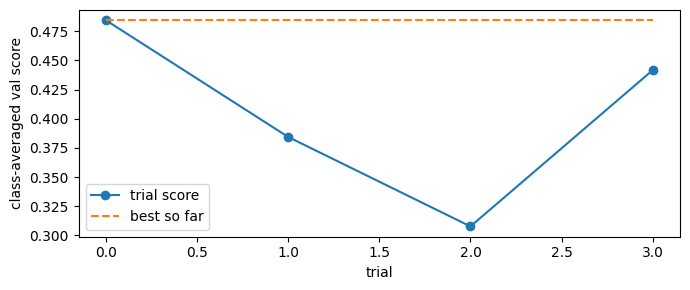

In [16]:
def objective(trial):
    hp = {"lr": trial.suggest_float("lr", 3e-4, 1.2e-3, log=True),
          "enc_mult": trial.suggest_float("enc_mult", 0.1, 0.5),
          "wd": WD,
          "cls_w": trial.suggest_float("cls_w", 0.1, 0.6),
          "dice_w": trial.suggest_float("dice_w", 0.5, 1.5),
          "rare_w": trial.suggest_float("rare_w", 1.0, 3.0),
          "boost": trial.suggest_float("boost", 0.8, 2.5)}
    seed_everything(SEED)
    model = build_unet(extra_enc, arch=extra_arch).to(device).to(memory_format=torch.channels_last)

    def report(ep, train_loss, val_loss, sc, lr):
        trial.report(sc["weighted"], ep)
        if trial.should_prune():
            raise optuna.TrialPruned()

    try:
        _, _, best = fit(model, hp, TUNE_EPOCHS, tune_idx, tune_val_idx, on_epoch=report)
    finally:
        del model
        torch.cuda.empty_cache()
    return best


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=4),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=1))
study.enqueue_trial(KNOWN_GOOD)
study.optimize(objective, n_trials=N_TRIALS)

trials = study.trials_dataframe()
trials.to_csv(f"{WORK}/optuna_trials.csv", index=False)
print(trials[["number", "value", "state"] + [c for c in trials.columns if c.startswith("params_")]].to_string(index=False))

best = study.best_params
HP = {"wd": WD, **{k: best[k] for k in ["lr", "enc_mult", "cls_w", "dice_w", "rare_w", "boost"]}}
HP_SCRATCH = {**HP, "lr": 1e-3}
print("\nbest trial score:", round(study.best_value, 4))
print("hyperparameters:", {k: round(v, 6) for k, v in HP.items()})

try:
    print("\nparameter importance:", {k: round(v, 3) for k, v in optuna.importance.get_param_importances(study).items()})
except Exception as e:
    print("importance not available:", str(e)[:80])

done = trials[trials["state"] == "COMPLETE"].sort_values("number")
plt.figure(figsize=(7, 3))
plt.plot(done["number"], done["value"], "o-", label="trial score")
plt.plot(done["number"], done["value"].cummax(), "--", label="best so far")
plt.xlabel("trial")
plt.ylabel("class-averaged val score")
plt.legend()
plt.tight_layout()
plt.savefig(f"{WORK}/optuna_history.png", dpi=120)
plt.show()


In [17]:
def run_experiment(name, make_model, encoder, pretrained, hp, epochs):
    seed_everything(SEED)
    config = {"seed": SEED, "encoder": encoder, "pretrained": pretrained, **hp, "decoder_attention": ATTN,
              "epochs": epochs, "batch_size": BATCH, "augmentations": AUGS,
              "loss": "class-weighted BCE + dice_w * batch dice + cls_w * presence BCE",
              "optimizer": "AdamW", "scheduler": "OneCycle", "weight_averaging": f"EMA {EMA_DECAY}",
              "hyperparameters_from": f"optuna ({N_TRIALS} trials)",
              "val_frac": VAL_FRAC, "image_size": f"{H}x{W}",
              "tta": "hflip" if USE_TTA else "none", "small_blob_filter": USE_BLOB_FILTER}
    run = wandb.init(project=WANDB_PROJECT, name=name, config=config, reinit=True)
    assert run is not None, "wandb run didn't start"
    print(f"\n=== {name} === {run.url}")

    model = make_model().to(device).to(memory_format=torch.channels_last)
    ckpt_path = f"{WORK}/{name}_best.pth"

    def log_epoch(ep, train_loss, val_loss, sc, lr):
        run.log({"train_loss": train_loss, "val_loss": val_loss, "val_fg_dice": sc["fg_dice"],
                 "val_fp_score": sc["fp_score"], "val_empty_acc": sc["empty_acc"],
                 "val_weighted": sc["weighted"], "lr": lr,
                 **{f"val_dice_{k}": sc[f"dice_{k}"] for k in short}}, step=ep)

    history, best_epoch, _ = fit(model, hp, epochs, train_idx, val_idx, ckpt_path=ckpt_path, on_epoch=log_epoch)

    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()
    print("best epoch:", best_epoch, "- tuning thresholds on val")
    seg, cls, gts = predict_val([model])
    params = tune_on_val(seg, cls, gts)
    masks = apply_post(seg, cls, params)
    report = class_report(masks, gts)
    tuned = macro_of(report)
    print(report.to_string(index=False))
    print("class-averaged val:", {k: round(v, 4) for k, v in tuned.items()})
    del seg, cls, masks, gts

    sub_path = f"{WORK}/submission_{name}.csv"
    write_submission(predict_test([model], params), sub_path)

    best_row = history[best_epoch - 1]
    run.summary.update({"best_epoch": best_epoch, "best_train_loss": best_row["train_loss"],
                        "best_val_loss": best_row["val_loss"],
                        **{f"tuned_{k}": v for k, v in tuned.items()},
                        "thresholds": {CLASSES[c]: params[c] for c in range(4)}})

    ckpt_art = wandb.Artifact(f"{name}-checkpoint", type="model")
    ckpt_art.add_file(ckpt_path)
    run.log_artifact(ckpt_art)
    sub_art = wandb.Artifact(f"{name}-submission", type="submission")
    sub_art.add_file(sub_path)
    run.log_artifact(sub_art)

    url, entity, run_id = run.url, run.entity, run.id
    run.finish()
    torch.cuda.empty_cache()
    return {"model": name, "net": model, "history": history, "sub_path": sub_path, "report": report,
            "best_epoch": best_epoch, "train_loss": best_row["train_loss"], "val_loss": best_row["val_loss"],
            "url": url, "entity": entity, "run_id": run_id, **tuned}


In [18]:
results = [
    run_experiment("scratch-unet", SmallUNet, "none (custom unet)", False, HP_SCRATCH, EPOCHS["scratch"]),
    run_experiment(second_name, lambda: build_unet(second_enc, arch=second_arch), f"{second_enc} ({second_arch})",
                   True, HP, EPOCHS["pretrained"]),
    run_experiment(extra_name, lambda: build_unet(extra_enc, arch=extra_arch), f"{extra_enc} ({extra_arch})", True, HP,
                   EPOCHS["additional"]),
]


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261112_042602-075frarr
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run scratch-unet
wandb: ⭐️ View project at https://wandb.ai/24f2002444/surface-defect-final-run3
wandb: 🚀 View run at https://wandb.ai/24f2002444/surface-defect-final-run3/runs/075frarr



=== scratch-unet === https://wandb.ai/24f2002444/surface-defect-final-run3/runs/075frarr
epoch 1/6  train 1.4116  val 1.0958  score 0.0815  dice [a 0.01 b 0.01 c 0.10 d 0.11]
epoch 2/6  train 0.9626  val 0.8921  score 0.2963  dice [a 0.00 b 0.00 c 0.12 d 0.34]
epoch 3/6  train 0.8719  val 0.8334  score 0.3395  dice [a 0.00 b 0.00 c 0.12 d 0.44]
epoch 4/6  train 0.8297  val 0.8011  score 0.3722  dice [a 0.00 b 0.00 c 0.26 d 0.49]
epoch 5/6  train 0.7999  val 0.7787  score 0.3939  dice [a 0.00 b 0.00 c 0.37 d 0.51]
epoch 6/6  train 0.7849  val 0.7707  score 0.3890  dice [a 0.00 b 0.00 c 0.39 d 0.54]
best epoch: 5 - tuning thresholds on val
  defect_a: thr=0.02 min_area=40 cls_thr=0.35 close=13 val_score=0.3290
  defect_b: thr=0.02 min_area=40 cls_thr=0.35 close=7 val_score=0.3111
  defect_c: thr=0.2 min_area=300 cls_thr=0.35 close=7 val_score=0.4525
  defect_d: thr=0.05 min_area=800 cls_thr=0.0 close=3 val_score=0.6239
   class  positives  found_%  dice_if_found  fg_dice  fp_score  empt

wandb: updating run metadata; uploading artifact scratch-unet-checkpoint; uploading artifact scratch-unet-submission
wandb: uploading artifact scratch-unet-checkpoint; uploading artifact scratch-unet-submission
wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: 
wandb: Run history:
wandb:            lr █▇▅▃▂▁
wandb:    train_loss █▃▂▂▁▁
wandb:    val_dice_a █▁▁▁▁▁
wandb:    val_dice_b █▁▁▁▁▁
wandb:    val_dice_c ▁▁▁▅██
wandb:    val_dice_d ▁▅▆▇██
wandb: val_empty_acc ▁▇████
wandb:   val_fg_dice ▁▃▄▆██
wandb:  val_fp_score ▁▇███▇
wandb:      val_loss █▄▂▂▁▁
wandb:            +1 ...
wandb: 
wandb: Run summary:
wandb:      best_epoch 5
wandb: best_train_loss 0.79986
wandb:   best_val_loss 0.7787
wandb:              lr 0.0
wandb:      train_loss 0.78485
wandb: tuned_empty_acc 0.83267
wandb:   tuned_fg_dice 0.24982
wandb:  tuned_fp_score 0.855
wandb:  tuned_weighted 0.42912
wandb:      val_dice_a 0.00048
wandb:              +8 ...
wandb: 
wandb: 🚀 View r


=== pretrained-tu-convnextv2_tiny-unet === https://wandb.ai/24f2002444/surface-defect-final-run3/runs/geszzkoa
epoch 1/10  train 1.3169  val 0.8327  score 0.3856  dice [a 0.03 b 0.00 c 0.46 d 0.59]
epoch 2/10  train 0.6698  val 0.5814  score 0.5420  dice [a 0.35 b 0.01 c 0.52 d 0.70]
epoch 3/10  train 0.5632  val 0.5311  score 0.6191  dice [a 0.38 b 0.32 c 0.56 d 0.73]
epoch 4/10  train 0.5064  val 0.4890  score 0.6358  dice [a 0.34 b 0.43 c 0.56 d 0.73]
epoch 5/10  train 0.4422  val 0.4648  score 0.6404  dice [a 0.35 b 0.43 c 0.57 d 0.73]
epoch 6/10  train 0.3921  val 0.4420  score 0.6462  dice [a 0.36 b 0.40 c 0.58 d 0.73]
epoch 7/10  train 0.3628  val 0.4233  score 0.6609  dice [a 0.39 b 0.44 c 0.57 d 0.74]
epoch 8/10  train 0.3333  val 0.4217  score 0.6610  dice [a 0.37 b 0.43 c 0.59 d 0.75]
epoch 9/10  train 0.3169  val 0.4198  score 0.6623  dice [a 0.38 b 0.42 c 0.60 d 0.75]
epoch 10/10  train 0.3138  val 0.4179  score 0.6658  dice [a 0.39 b 0.44 c 0.59 d 0.75]
best epoch: 10 - 

wandb: updating run metadata; uploading artifact pretrained-tu-convnextv2_tiny-unet-checkpoint; uploading artifact pretrained-tu-convnextv2_tiny-unet-submission
wandb: uploading artifact pretrained-tu-convnextv2_tiny-unet-checkpoint; uploading artifact pretrained-tu-convnextv2_tiny-unet-submission
wandb: uploading artifact pretrained-tu-convnextv2_tiny-unet-checkpoint
wandb: uploading data
wandb: 
wandb: Run history:
wandb:            lr ▆██▇▅▄▃▂▁▁
wandb:    train_loss █▃▃▂▂▂▁▁▁▁
wandb:    val_dice_a ▁▇█▇▇▇████
wandb:    val_dice_b ▁▁▆██▇████
wandb:    val_dice_c ▁▄▆▆▇▇▇███
wandb:    val_dice_d ▁▆▇▇▇▇████
wandb: val_empty_acc ▁▆▇▇▇█████
wandb:   val_fg_dice ▁▄▇▇▇▇████
wandb:  val_fp_score ▁▇▇▇▇█████
wandb:      val_loss █▄▃▂▂▁▁▁▁▁
wandb:            +1 ...
wandb: 
wandb: Run summary:
wandb:      best_epoch 10
wandb: best_train_loss 0.31384
wandb:   best_val_loss 0.41793
wandb:              lr 0.0
wandb:      train_loss 0.31384
wandb: tuned_empty_acc 0.94558
wandb:   tuned_fg_dice 0.5570


=== tu-convnext_tiny-unet === https://wandb.ai/24f2002444/surface-defect-final-run3/runs/pycbb46b
epoch 1/14  train 1.3789  val 0.9574  score 0.2789  dice [a 0.03 b 0.01 c 0.21 d 0.43]
epoch 2/14  train 0.7234  val 0.6370  score 0.5029  dice [a 0.30 b 0.01 c 0.50 d 0.68]
epoch 3/14  train 0.6059  val 0.5773  score 0.5717  dice [a 0.28 b 0.37 c 0.47 d 0.68]
epoch 4/14  train 0.5477  val 0.5368  score 0.5949  dice [a 0.30 b 0.41 c 0.50 d 0.70]
epoch 5/14  train 0.4912  val 0.5176  score 0.6028  dice [a 0.34 b 0.36 c 0.51 d 0.70]
epoch 6/14  train 0.4579  val 0.4899  score 0.6205  dice [a 0.34 b 0.39 c 0.55 d 0.70]
epoch 7/14  train 0.4425  val 0.4715  score 0.6179  dice [a 0.32 b 0.37 c 0.54 d 0.72]
epoch 8/14  train 0.4213  val 0.4660  score 0.6232  dice [a 0.34 b 0.36 c 0.56 d 0.71]
epoch 9/14  train 0.3819  val 0.4537  score 0.6317  dice [a 0.34 b 0.38 c 0.56 d 0.71]
epoch 10/14  train 0.3760  val 0.4415  score 0.6374  dice [a 0.35 b 0.38 c 0.56 d 0.72]
epoch 11/14  train 0.3424  val

wandb: updating run metadata; uploading artifact tu-convnext_tiny-unet-checkpoint; uploading artifact tu-convnext_tiny-unet-submission
wandb: uploading artifact tu-convnext_tiny-unet-checkpoint; uploading artifact tu-convnext_tiny-unet-submission
wandb: uploading artifact tu-convnext_tiny-unet-checkpoint
wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: 
wandb: Run history:
wandb:            lr ▄███▇▆▅▅▄▃▂▁▁▁
wandb:    train_loss █▄▃▃▂▂▂▂▁▁▁▁▁▁
wandb:    val_dice_a ▁▇▇▇██████████
wandb:    val_dice_b ▁▁▇█▇█▇▇▇█████
wandb:    val_dice_c ▁▆▆▆▇▇▇███████
wandb:    val_dice_d ▁▇▇▇▇▇██▇█████
wandb: val_empty_acc ▁▆▆▇▇▇▇███████
wandb:   val_fg_dice ▁▅▇▇▇█▇███████
wandb:  val_fp_score ▁▆▆▇▇▇████████
wandb:      val_loss █▄▃▃▂▂▂▂▁▁▁▁▁▁
wandb:            +1 ...
wandb: 
wandb: Run summary:
wandb:      best_epoch 12
wandb: best_train_loss 0.32926
wandb:   best_val_loss 0.4182
wandb:              lr 0.0
wandb:      train_loss 0.31114
wandb: tuned_empty_acc 0.94

## Inference step: ensemble of the two pretrained models
Averages the two pretrained UNets' probabilities (same horizontal-flip TTA) and tunes thresholds on the
validation split like for the single models. It is only used if it beats all three single models.

In [19]:
ens_name = "ensemble-pretrained-pair"
ens_models = [r["net"] for r in results[1:]]
ens = None
if USE_ENSEMBLE:
    print("tuning", ens_name)
    seg, cls, gts = predict_val(ens_models)
    ens_params = tune_on_val(seg, cls, gts)
    ens_masks = apply_post(seg, cls, ens_params)
    ens_report = class_report(ens_masks, gts)
    ens = {"model": ens_name, "report": ens_report, "params": ens_params, "train_loss": np.nan,
           "val_loss": np.nan, "best_epoch": np.nan, **macro_of(ens_report)}
    print(ens_report.to_string(index=False))
    del seg, cls, ens_masks, gts


tuning ensemble-pretrained-pair
  defect_a: thr=0.1 min_area=40 cls_thr=0.1 close=3 val_score=0.5762
  defect_b: thr=0.02 min_area=40 cls_thr=0.0 close=3 val_score=0.6310
  defect_c: thr=0.2 min_area=40 cls_thr=0.35 close=0 val_score=0.6978
  defect_d: thr=0.2 min_area=500 cls_thr=0.2 close=0 val_score=0.8238
   class  positives  found_%  dice_if_found  fg_dice  fp_score  empty_acc  weighted
defect_a        162     71.6         0.5822   0.4169    0.9554     0.9327    0.5762
defect_b         48     81.2         0.5977   0.4856    0.9717     0.9672    0.6310
defect_c        615     88.0         0.6879   0.6051    0.9186     0.9046    0.6978
defect_d        256     93.4         0.8142   0.7601    0.9745     0.9684    0.8238


## Comparing the models

                             model  fg_dice  empty_acc  fp_score  weighted  train_loss  val_loss  best_epoch  dice_a  dice_b  dice_c  dice_d
          ensemble-pretrained-pair   0.5669     0.9432    0.9550    0.6822         NaN       NaN         NaN  0.4169  0.4856  0.6051  0.7601
pretrained-tu-convnextv2_tiny-unet   0.5571     0.9456    0.9589    0.6763      0.3138    0.4179        10.0  0.4044  0.4548  0.6034  0.7657
             tu-convnext_tiny-unet   0.5294     0.9414    0.9598    0.6567      0.3293    0.4182        12.0  0.3534  0.4423  0.5877  0.7344
                      scratch-unet   0.2498     0.8327    0.8550    0.4291      0.7999    0.7787         5.0  0.0884  0.0306  0.3480  0.5323


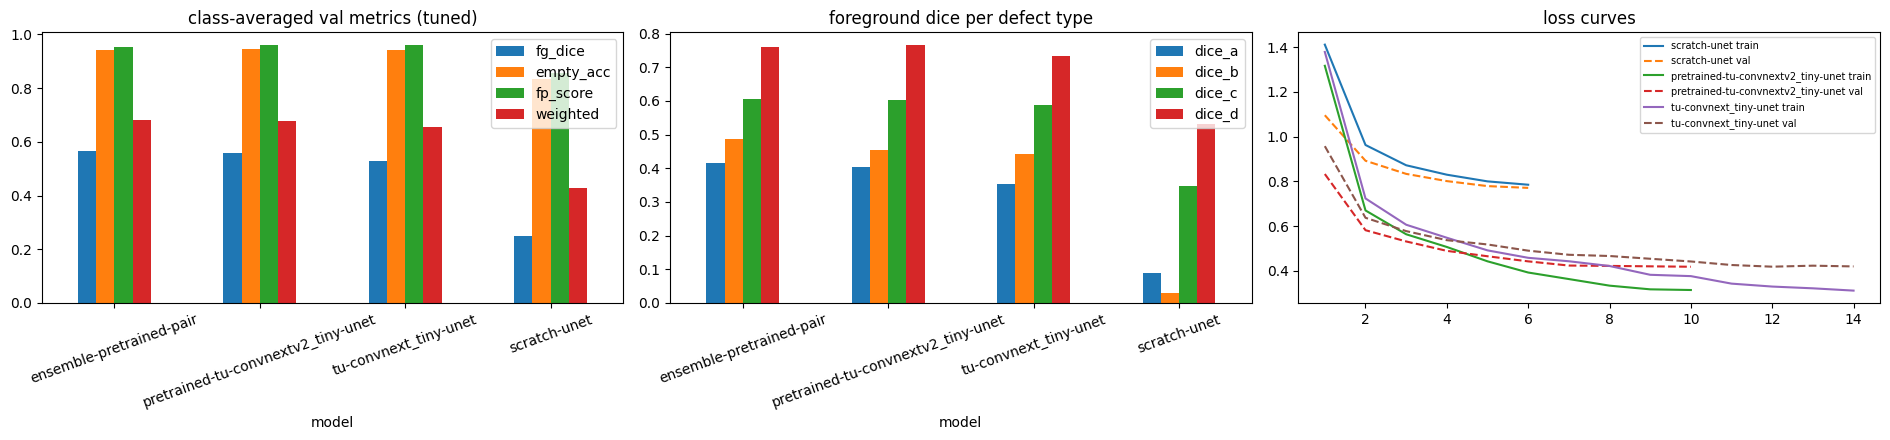

In [20]:
entries = results + ([ens] if ens else [])
rows = []
for r in entries:
    row = {"model": r["model"], "fg_dice": r["fg_dice"], "empty_acc": r["empty_acc"], "fp_score": r["fp_score"],
           "weighted": r["weighted"], "train_loss": r["train_loss"], "val_loss": r["val_loss"],
           "best_epoch": r["best_epoch"]}
    for c in range(4):
        row[f"dice_{short[c]}"] = r["report"]["fg_dice"].iloc[c]
    rows.append(row)

comp = pd.DataFrame(rows).sort_values("weighted", ascending=False).round(4).reset_index(drop=True)
comp.to_csv(f"{WORK}/model_comparison.csv", index=False)
print(comp.to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
comp.set_index("model")[["fg_dice", "empty_acc", "fp_score", "weighted"]].plot.bar(ax=ax[0], rot=20)
ax[0].set_title("class-averaged val metrics (tuned)")
comp.set_index("model")[[f"dice_{k}" for k in short]].plot.bar(ax=ax[1], rot=20)
ax[1].set_title("foreground dice per defect type")
for r in results:
    h = pd.DataFrame(r["history"])
    ax[2].plot(h["epoch"], h["train_loss"], label=f"{r['model']} train")
    ax[2].plot(h["epoch"], h["val_loss"], "--", label=f"{r['model']} val")
ax[2].set_title("loss curves")
ax[2].legend(fontsize=7)
plt.tight_layout()
plt.savefig(f"{WORK}/model_comparison.png", dpi=120)
plt.show()


In [21]:
win, runner = comp.iloc[0], comp.iloc[1]
reports = {r["model"]: r["report"] for r in entries}
best_on = [CLASSES[c] for c in range(4) if win[f"dice_{short[c]}"] >= comp[f"dice_{short[c]}"].max() - 1e-9]
lines = [
    f"Final model: {win['model']}",
    f"- highest class-averaged validation score: {win['weighted']:.4f} (runner-up {runner['model']}: {runner['weighted']:.4f})",
    f"- foreground dice {win['fg_dice']:.4f}, empty-mask accuracy {win['empty_acc']:.4f}, false-positive score {win['fp_score']:.4f}",
]
if win["model"] == ens_name:
    lines.append("- it averages the two pretrained models, so train/val loss are those of its members (see the table)")
else:
    lines.append(f"- train loss {win['train_loss']:.4f} vs val loss {win['val_loss']:.4f} "
                 f"(gap {win['val_loss'] - win['train_loss']:.4f})")
lines += [
    f"- best foreground dice on: {', '.join(best_on) if best_on else 'no single defect type'}",
    f"- Kaggle cutoff is 0.65 and the validation score is {'above' if win['weighted'] >= 0.65 else 'below'} it "
    f"(the leaderboard is the real check)",
    "- where the winner loses points:",
]
for _, row in reports[win["model"]].iterrows():
    limit = "missed defects" if row["found_%"] < 75 else "mask quality"
    lines.append(f"    {row['class']}: finds {row['found_%']}% of real defects, dice {row['dice_if_found']} on the ones "
                 f"it finds (main limit: {limit})")
print("\n".join(lines))
with open(f"{WORK}/final_choice.md", "w") as f:
    f.write("\n".join(lines) + "\n")


Final model: ensemble-pretrained-pair
- highest class-averaged validation score: 0.6822 (runner-up pretrained-tu-convnextv2_tiny-unet: 0.6763)
- foreground dice 0.5669, empty-mask accuracy 0.9432, false-positive score 0.9550
- it averages the two pretrained models, so train/val loss are those of its members (see the table)
- best foreground dice on: defect_a, defect_b, defect_c
- Kaggle cutoff is 0.65 and the validation score is above it (the leaderboard is the real check)
- where the winner loses points:
    defect_a: finds 71.6% of real defects, dice 0.5822 on the ones it finds (main limit: missed defects)
    defect_b: finds 81.2% of real defects, dice 0.5977 on the ones it finds (main limit: mask quality)
    defect_c: finds 88.0% of real defects, dice 0.6879 on the ones it finds (main limit: mask quality)
    defect_d: finds 93.4% of real defects, dice 0.8142 on the ones it finds (main limit: mask quality)


In [22]:
if win["model"] == ens_name:
    final_sub = f"{WORK}/submission_{ens_name}.csv"
    write_submission(predict_test(ens_models, ens["params"]), final_sub)
else:
    final_sub = {r["model"]: r["sub_path"] for r in results}[win["model"]]
shutil.copy(final_sub, f"{WORK}/submission.csv")

final = pd.read_csv(f"{WORK}/submission.csv", keep_default_na=False)
print("submission:", final.shape, list(final.columns))
print("share of empty masks:", round((final["mask_rle"].str.strip() == "").mean(), 3))
print(final.head())


submission: (12000, 4) ['ID', 'image_id', 'defect_type', 'mask_rle']
share of empty masks: 0.767
   ID    image_id defect_type mask_rle
0   1  WAFNKCRR7Q    defect_a         
1   2  WAFNKCRR7Q    defect_b         
2   3  WAFNKCRR7Q    defect_c         
3   4  WAFNKCRR7Q    defect_d         
4   5  YZXKEWSUDD    defect_a         


In [23]:
try:
    run = wandb.init(project=WANDB_PROJECT, id=results[-1]["run_id"], resume="must")
    run.summary.update({"final_model": win["model"], "final_val_weighted": float(win["weighted"]),
                        "final_val_fg_dice": float(win["fg_dice"])})
    art = wandb.Artifact("final-submission", type="submission")
    art.add_file(f"{WORK}/submission.csv")
    art.add_file(f"{WORK}/final_choice.md")
    run.log_artifact(art)
    run.finish()
except Exception as e:
    print("couldn't attach the final submission to the W&B run:", str(e)[:120])

print("W&B project page:", results[0]["url"].rsplit("/runs/", 1)[0])
try:
    api = wandb.Api()
    for r in api.runs(f"{results[0]['entity']}/{WANDB_PROJECT}"):
        print(f"  {r.name}: {r.state}")
except Exception as e:
    print("couldn't list the runs through the W&B API:", str(e)[:100])


wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261112_063220-pycbb46b
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run tu-convnext_tiny-unet
wandb: ⭐️ View project at https://wandb.ai/24f2002444/surface-defect-final-run3
wandb: 🚀 View run at https://wandb.ai/24f2002444/surface-defect-final-run3/runs/pycbb46b
wandb: updating run metadata; uploading artifact final-submission
wandb: uploading artifact final-submission
wandb: uploading wandb-metadata.json
wandb: 
wandb: Run summary:
wandb:                   best_epoch 12
wandb:              best_train_loss 0.32926
wandb:                best_val_loss 0.4182
wandb:                  final_model ensemble-pretrained-...
wandb:            final_val_fg_dice 0.5669
wandb:           final_val_weighted 0.6822
wandb:                           lr 0.0
wandb:    thresholds.defect_a.close 0
wandb:  thresholds.defect_a.cls_thr 0
wandb: thresholds.defect_a.min_area 80
wandb: 

W&B project page: https://wandb.ai/24f2002444/surface-defect-final-run3
  scratch-unet: finished
  pretrained-tu-convnextv2_tiny-unet: finished
  tu-convnext_tiny-unet: finished
